# Lab 07: How the OpenAI Agents SDK runs your loop

## Goal

Rebuild the Chinook desk agent in the OpenAI Agents SDK and read what its `Runner` did, item by item and span by span,
as the loop we wrote by hand in lab 04. Every SDK call is a coroutine, so the lab starts with `await`. The moment that
teaches the framework comes in Part F, when one question needs two specialists. Asked *How many invoices does Puja
Srivastava have, what do they add up to, and who is her support rep?*, a triage agent that **hands the question off**
to the invoices specialist loses the rep every time we ran it (6 of 6 runs in the saved notebook): control moved to an agent with no
rep tool and never came back. The same two specialists **used as tools** answer all three facts (6 of 6), at
8 model requests against 3 for one agent with all three tools.

## What you will learn

- how `async def`, `await` and `asyncio.gather` work, and why two model calls made with `AsyncOpenAI` finish in
  about the time of the slower one;
- how to turn plain Python functions into tools with `function_tool`, give them to an `Agent`, and run it with
  `Runner.run`;
- how to read a run as the loop from lab 04: the `RunResult` (`new_items`, `raw_responses`, `usage`) and a trace of
  the run, kept in the notebook;
- why every agent here sets `ModelSettings` from `models.env`, and how to read the effort the API really used;
- how to keep a conversation across runs with `SQLiteSession`;
- how to wire two specialists as tools and as a handoff, say who controls the next step in each, and what each costs.

## Where this lab starts

Lab 04 wrote the agent loop by hand on Chat Completions. Each pass was one **turn**:

1. Send the whole message list and the tool schemas to the model.
2. Append the reply. If the model wrote text, that is the answer: stop.
3. Otherwise run every tool call it asked for, append one result per call, and go back to step 1.
4. Stop anyway after a fixed number of turns (the turn cap).

The OpenAI Agents SDK is that loop as a library: a `Runner` runs it, an `Agent` holds what the loop needs (the
instructions, the model, the tools), and the run comes back as an object we can read. The SDK talks to OpenAI's
Responses API, the newer API that labs 01 and 06 showed, rather than Chat Completions. This lab restates the three
lookups and everything else it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model and prices from
`models.env`, and takes the key from `.env` without printing it (lab 00 explains it line by line). This lab adds
`asyncio`, `json`, `re`, `sqlite3` and `time`, all from Python's standard library.

In [1]:
from pathlib import Path
import asyncio
import json
import os
import re
import sqlite3
import time
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Wait for two model calls at once with async

Every call to the SDK is written `await Runner.run(...)`. Lab 06 used `await` with one sentence of explanation; here
we open the word, because a framework's `await` copied without understanding is where confusing errors start. We
climb in small steps: a normal function, the same function with `async`, what `await` does, two waits one after the
other, two waits at once, then two real model calls.

### A normal function returns its value

A normal `def` runs from its first line to its `return`, and the caller gets the result.

In [2]:
def greet(name):
    return "hello " + name


print(greet("Helena"))
print("type of the return:", type(greet("Helena")).__name__)

hello Helena
type of the return: str


A string, as expected. Now the same body with `async` before `def`, which makes it a **coroutine function**. We call
it the same way and look at what comes back, without `await`.

In [3]:
async def greet_async(name):
    return "hello " + name


ticket = greet_async("Helena")
print(ticket)
print("type of the return:", type(ticket).__name__)

<coroutine object greet_async at 0x106a9c700>
type of the return: coroutine


The call did not run the body. It returned a **coroutine**: an object that holds work which has not started yet,
like a ticket for it. `"hello Helena"` exists nowhere so far.

`await` runs the coroutine to its end and gives back its result. In a notebook we can write `await` directly in a
cell, because Jupyter runs an **event loop** for us: the part of Python's `asyncio` that runs coroutines and switches
between them while they wait. In a `.py` file there is no running loop, so the top call goes inside
`asyncio.run(main())`.

In [4]:
result = await ticket
print(result)
print("type of the return:", type(result).__name__)

hello Helena
type of the return: str


Now the string. A coroutine runs once: awaiting `ticket` a second time would raise an error, so each call makes a new
one.

### Why `async` at all: a wait that lets go

`await` is not only a way to get a result. While a coroutine waits for something slow (a network reply, a database,
a timer), it can hand control back to the event loop, which runs other coroutines in the meantime. A model call is
almost all waiting: the request goes out, and our program has nothing to do until the reply comes back.

`asyncio.sleep(seconds)` is the simplest wait that lets go. `pause` prints when it starts and when it is done, so we
can see the order.

In [5]:
async def pause(name, seconds):
    print("start", name)
    await asyncio.sleep(seconds)
    print("done ", name)
    return name


print("returned:", await pause("alone", 0.3))

start alone


done  alone
returned: alone


### Two waits, one after the other

`await` one, then `await` the other: the second does not start until the first is done, so two one-second waits
should take about **two** seconds. `time.perf_counter()` reads a clock in seconds; the difference between two readings
is the time between them.

In [6]:
t0 = time.perf_counter()
first = await pause("a", 1)
second = await pause("b", 1)
print("results:", first, second)
print("one after the other:", round(time.perf_counter() - t0, 2), "seconds")

start a


done  a
start b


done  b
results: a b
one after the other: 2.0 seconds


`start a`, `done a`, then `start b`, `done b`: 2.0 seconds in all. This is the `for call in ...` of lab 04,
which ran tool calls one after another.

### Two waits at once with `asyncio.gather`

`asyncio.gather(...)` takes coroutines (the tickets, not their results), starts them all, and waits until the last
one is done. It returns a list of results **in the order of its arguments**, whichever finished first. Before you
run it: how long will two one-second waits take, and in which order will the four lines print?

In [7]:
t0 = time.perf_counter()
together = await asyncio.gather(pause("a", 1), pause("b", 1))
print("results:", together)
print("gathered:", round(time.perf_counter() - t0, 2), "seconds")

start a
start b


done  a
done  b
results: ['a', 'b']
gathered: 1.01 seconds


Both `start` lines come before both `done` lines: `b` started while `a` was still waiting. The clock says
1.01 seconds, the time of the slower wait rather than the sum, and the results come back as `['a', 'b']`,
in argument order.

**⚠️ A wait that does not let go blocks everything.** `time.sleep` is an ordinary wait: it holds the whole program,
event loop included, so nothing else runs during it. Put inside an `async def`, it still blocks, and `gather` cannot
overlap anything:

In [8]:
async def pause_blocking(name, seconds):
    print("start", name)
    time.sleep(seconds)  # an ordinary wait: the event loop cannot run anything else meanwhile
    print("done ", name)
    return name


t0 = time.perf_counter()
await asyncio.gather(pause_blocking("a", 1), pause_blocking("b", 1))
print("gathered, but blocking:", round(time.perf_counter() - t0, 2), "seconds")

start a


done  a
start b


done  b
gathered, but blocking: 2.01 seconds


2.01 seconds, and the lines print in sequence again: `async def` alone did nothing. The same thing happens with
any library call that waits without `await`, such as the ordinary `OpenAI` client of labs 01 to 06: wrapped in an
`async def`, its calls still run one after another. For model calls at once we need a client whose calls are
coroutines.

### Two real model calls, one after the other and together

`AsyncOpenAI` is the same client as `OpenAI` with every method made a coroutine function, so each call must be
awaited. `ask` sends one question on the Responses API (the API the Agents SDK uses) and returns the reply's text:

- `input` is the question; `max_output_tokens` caps the reply;
- `reasoning={"effort": EFFORT or omit}` passes the effort from `models.env`; `omit` is the `openai` package's marker
  for "leave this out", so a model with no reasoning setting (an empty `REASONING_EFFORT`) gets none;
- `response.output_text` joins the text parts of the reply.

The two questions do not depend on each other, which is what makes running them together safe.

In [9]:
from openai import AsyncOpenAI, omit

aclient = AsyncOpenAI()


async def ask(question):
    response = await aclient.responses.create(
        model=MODEL,
        input=question,
        reasoning={"effort": EFFORT or omit},
        max_output_tokens=200,
    )
    return response.output_text


QUESTIONS = [
    "In one sentence, what is an invoice?",
    "In one sentence, what does a customer support rep do?",
]

t0 = time.perf_counter()
for question in QUESTIONS:
    print(await ask(question))
print("one after the other:", round(time.perf_counter() - t0, 2), "seconds")

An invoice is a document requesting payment for goods or services provided.


A customer support representative helps customers resolve issues, answer questions, and use a company’s products or services.
one after the other: 6.93 seconds


In [10]:
t0 = time.perf_counter()
answers = await asyncio.gather(*[ask(question) for question in QUESTIONS])
for answer in answers:
    print(answer)
print("gathered:", round(time.perf_counter() - t0, 2), "seconds")

An invoice is a document that lists the goods or services provided, their costs, and the amount due for payment.
A customer support representative helps customers resolve questions and problems with a company’s products or services.
gathered: 1.95 seconds


`[ask(question) for question in QUESTIONS]` builds a list of two coroutines without running them, and the `*` passes
them to `gather` as two separate arguments. Reading the two runs:

- one after the other: 6.93 seconds, the time of both calls added up;
- gathered: 1.95 seconds: the two waits overlapped, so the total is set by the slower call, not by the sum;
- the answers come back in the order of `QUESTIONS` either way.

The same call does not take the same time twice (a model call can vary by a second or more), so your seconds will
differ: compare the two totals, not the digits. Gathering is right only when the calls are independent: lab 04's Helena question
could not gather `find_customer` with `get_invoices`, because the second needs the `customer_id` the first returns.

**In production:** `asyncio.TaskGroup` (Python 3.11 and later) does what `gather` does, and cancels the other tasks
when one fails; a server that answers many people at once is built on the same event loop.

**Checkpoint A.** Two one-second sleeps take about 2 seconds awaited one after the other and about 1 second gathered,
with results in argument order; `time.sleep` inside `async def` stays at about 2; two real calls gathered take about
as long as the slower one. In Part F, `gather` runs two agents at once.

---

## Part B: Define the desk agent in the SDK

An agent needs tools, and a tool starts as a plain function. This part writes the three Chinook lookups from lab 04,
calls them by hand so we know the right answers, then turns one into an SDK tool and compares what the SDK generates
with the schema lab 03 wrote by hand.

### The three lookups, called by hand

The shop's data is `data/chinook.db`, a SQLite file, opened read-only (`mode=ro`) so no tool can change it, and with
`check_same_thread=False` because the SDK may run a tool on another thread than the one that opened the connection.

The functions are lab 04's, with two additions the SDK reads: **type hints** (`name: str`, `-> list[dict]`), which
give each argument its JSON type, and a **docstring**, whose first lines become the tool's description and whose
`Args:` section describes each argument.

In [11]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}


for name in ["Helena Holý", "Puja Srivastava"]:
    customer = find_customer(name)[0]
    print(customer, get_invoices(customer["customer_id"]), get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'} {'customer_id': 6, 'invoice_count': 7, 'total': 49.62} {'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'} {'customer_id': 59, 'invoice_count': 6, 'total': 36.64} {'customer_id': 59, 'support_rep': 'Jane Peacock'}


These are the facts every answer in this lab is checked against:

1. **Helena Holý** is customer 6: **7 invoices** adding up to **$49.62**, support rep **Steve Johnson**.
2. **Puja Srivastava** is customer 59: **6 invoices** adding up to **$36.64**, support rep **Jane Peacock**.

Helena is the question the desk agent answers in Parts C to E. Puja is the question of Part F: Chinook is a public
sample database, and a model may know Helena's numbers from its training data, so the harder test uses the customer
it is less likely to have seen.

### From a function to a tool with `function_tool`

Lab 03 described `find_customer` to the model by hand: a JSON schema with a name, a description, the parameters and
`"strict": True`, which needs every property in `required` and `additionalProperties: False`. Here it is again, as
the `function` part of that tool:

In [12]:
HAND_WRITTEN = {
    "name": "find_customer",
    "description": "Find a shop customer by full name. Returns a list of matches with their customer_id.",
    "strict": True,
    "parameters": {
        "type": "object",
        "properties": {"name": {"type": "string", "description": "First and last name, for example 'Ana Silva'"}},
        "required": ["name"],
        "additionalProperties": False,
    },
}
print(json.dumps(HAND_WRITTEN["parameters"], indent=2))

{
  "type": "object",
  "properties": {
    "name": {
      "type": "string",
      "description": "First and last name, for example 'Ana Silva'"
    }
  },
  "required": [
    "name"
  ],
  "additionalProperties": false
}


`function_tool` is the SDK's way to build that from the function. We call it as a plain function on
`find_customer` (it also works as a `@function_tool` decorator, but that would replace our function by the tool, and
we want to keep calling the plain function). It returns a `FunctionTool` object; we print what the model will see.

In [13]:
from agents import function_tool

find_customer_tool = function_tool(find_customer)

print(type(find_customer_tool).__name__)
print("name:       ", find_customer_tool.name)
print("description:", find_customer_tool.description)
print("strict:     ", find_customer_tool.strict_json_schema)
print(json.dumps(find_customer_tool.params_json_schema, indent=2))

FunctionTool
name:        find_customer
description: Find a shop customer by full name. Returns a list of matches with their customer_id.
strict:      True
{
  "properties": {
    "name": {
      "description": "First and last name, for example 'Ana Silva'.",
      "title": "Name",
      "type": "string"
    }
  },
  "required": [
    "name"
  ],
  "title": "find_customer_args",
  "type": "object",
  "additionalProperties": false
}


Field by field, against the hand-written schema:

| Hand-written (lab 03) | Generated by `function_tool` | Where the SDK took it from |
|---|---|---|
| `"name": "find_customer"` | `name: find_customer` | the function's name |
| the description string | `description: Find a shop customer ...` | the docstring's first lines |
| `"type": "string"` for `name` | `"type": "string"` | the type hint `name: str` |
| the argument's description | `"description": "First and last name, ..."` | the docstring's `Args:` section |
| `"required": ["name"]`, `"additionalProperties": false` | the same | strict mode, on by default (`strict: True`) |

The extra `"title"` keys are labels the SDK's schema generator adds; the model can ignore them. Nothing here is new:
the SDK writes the same schema we wrote by hand, from the code we already have. The function's body is never sent; as
in lab 03, the model only sees this description and asks for a call, and our code runs it.

The other two lookups become tools the same way.

In [14]:
DESK_TOOLS = [find_customer_tool, function_tool(get_invoices), function_tool(get_support_rep)]
print([tool.name for tool in DESK_TOOLS])
print(DESK_TOOLS[1].params_json_schema["properties"])

['find_customer', 'get_invoices', 'get_support_rep']
{'customer_id': {'title': 'Customer Id', 'type': 'integer'}}


`get_invoices` takes `customer_id` as an `integer`, from the hint `customer_id: int`.

### The agent

An `Agent` holds what lab 04's loop needed besides the messages: the system prompt (here `instructions`), the model
and the tools. It also takes `model_settings`, the request settings the SDK sends on every model call. We set the
reasoning effort from `models.env` there; Part D shows what happens without it.

In [15]:
from agents import Agent, ModelSettings
from openai.types.shared import Reasoning

SETTINGS = ModelSettings(reasoning=Reasoning(effort=EFFORT))
SYSTEM = ("You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. "
          "Answer in one or two sentences.")

desk = Agent(name="Desk", instructions=SYSTEM, model=MODEL, tools=DESK_TOOLS, model_settings=SETTINGS)

print("name:          ", desk.name)
print("instructions:  ", desk.instructions)
print("tools:         ", [tool.name for tool in desk.tools])
print("model_settings:", desk.model_settings.reasoning)

name:           Desk
instructions:   You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. Answer in one or two sentences.
tools:          ['find_customer', 'get_invoices', 'get_support_rep']
model_settings: Reasoning(context=None, effort='none', generate_summary=None, mode=None, summary=None)


The agent is a description, not a running process: nothing has been sent to the model yet. `draw_graph`, from the SDK's
visualization extension, draws what the agent can reach. It needs the Graphviz `dot` program (see Troubleshooting if
the cell fails).

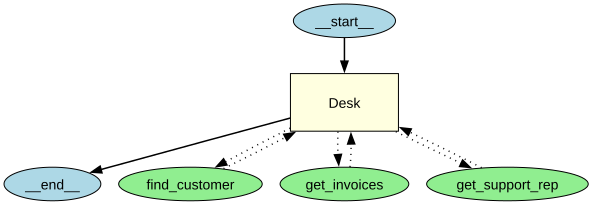

In [16]:
from agents.extensions.visualization import draw_graph

draw_graph(desk)

How to read the drawing:

- `__start__` and `__end__` (blue) are where a run enters and leaves;
- the yellow box is the agent, `Desk`;
- each green ellipse is a tool, joined to the agent by dotted arrows both ways: the agent asks for the tool, and the
  result comes back to the same agent.

**Checkpoint B.** Helena 6, 7, 49.62, Steve Johnson and Puja 59, 6, 36.64, Jane Peacock from the plain functions; a
`FunctionTool` whose schema matches lab 03's (strict, `name` a string, the description from the docstring); a
`Desk` agent with three tools, drawn with three green ellipses.

---

## Part C: Read what the runner did

`Runner.run(agent, input)` runs the loop and returns a `RunResult`. This part reads that object until we can point at
each turn of lab 04's loop in it, and then reads the **trace** of the same run: the timed record of every step,
which the SDK builds as it goes.

### Keep the trace in the notebook

By default the SDK uploads every run's trace to the OpenAI dashboard (the Traces page on platform.openai.com). That
page belongs to the organisation that owns the API key, so on a shared class key you may not be able to open it, and
a reader of this notebook would see nothing. We keep the trace here instead.

The SDK hands each finished piece of a trace, a **span**, to its **trace processors**. `set_trace_processors`
replaces the default one (the uploader) with ours, which only appends each span to a list. `TracingProcessor` is an
abstract class: the SDK calls six methods on every processor, so Python refuses to create one that does not define all
six. Only `on_span_end` does anything here; the other five are one-line methods that do nothing (`pass`).

In [17]:
from agents import set_trace_processors
from agents.tracing import TracingProcessor


class SpanRecorder(TracingProcessor):
    """Keep every finished span in a list in this notebook, instead of uploading it."""

    def __init__(self):
        self.spans = []

    def on_span_end(self, span):
        self.spans.append(span)

    def on_span_start(self, span): pass
    def on_trace_start(self, trace): pass
    def on_trace_end(self, trace): pass
    def shutdown(self): pass
    def force_flush(self): pass


recorder = SpanRecorder()
set_trace_processors([recorder])
print("trace processors: our recorder only; nothing is uploaded")

trace processors: our recorder only; nothing is uploaded


### A time limit on every model request

The runner sends its requests through an `AsyncOpenAI` client that the SDK creates for us. That client waits up to ten
minutes for an answer and then tries twice more, so one request the API never answers can hold a cell for half an
hour, and Jupyter's stop button cannot break that wait. We give the SDK our own client with a 60-second limit: a
request that gets no answer fails and is sent again, and a run that still cannot finish raises an error we can read.
A production agent needs the same limit, set a little above its slowest normal call.

In [18]:
from agents import set_default_openai_client

set_default_openai_client(AsyncOpenAI(timeout=60, max_retries=2))
print("model requests: 60 s time limit, 2 retries")

model requests: 60 s time limit, 2 retries


### Run the desk agent on the Helena question

The question is lab 04's. `Runner.run` is a coroutine function, so we `await` it.

In [19]:
from agents import Runner

QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

recorder.spans.clear()
result = await Runner.run(desk, QUESTION)

print(type(result).__name__)
print(result.final_output)

RunResult
Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


A `RunResult`, and its `final_output`: *Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.* The three facts match the lookups (7, $49.62, Steve Johnson).
But a right answer says nothing about how it was reached. Three fields of the result do.

### `new_items`: what happened, in order

`result.new_items` is a list of the items the run added to the conversation. Each has a `type`; the ones we will see:

- `tool_call_item`: the model asked for a tool (its `raw_item` holds the `name` and the JSON `arguments`);
- `tool_call_output_item`: our code ran it (its `output` is what the function returned);
- `message_output_item`: the model wrote text.

In [20]:
for item in result.new_items:
    if item.type == "tool_call_item":
        print(f"{item.type:22} {item.raw_item.name}({item.raw_item.arguments})")
    elif item.type == "tool_call_output_item":
        print(f"{item.type:22} {item.output}")
    else:
        print(f"{item.type:22} {item.raw_item.content[0].text}")

tool_call_item         find_customer({"name":"Helena Holý"})
tool_call_output_item  [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
tool_call_item         get_invoices({"customer_id":6})
tool_call_item         get_support_rep({"customer_id":6})
tool_call_output_item  {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
tool_call_output_item  {'customer_id': 6, 'support_rep': 'Steve Johnson'}
message_output_item    Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Read top to bottom, this is lab 04's run:

- `find_customer` with `{"name":"Helena Holý"}`, and its result, a list with customer 6;
- `get_invoices` and `get_support_rep`, both with `customer_id` 6, listed together before their two results: the model
  asked for both in one reply;
- the message with the answer.

The outputs are our functions' return values. The model received them as text: the SDK turns a returned list or
dict into a string with `str()` before it goes into the request, so a function can return any Python value.

### `raw_responses`: one entry per model call

`new_items` does not say where one turn ends and the next begins. `result.raw_responses` does: one `ModelResponse` per
call to the model, each with the output items of that call.

In [21]:
print("model calls:", len(result.raw_responses))
for turn, response in enumerate(result.raw_responses, start=1):
    print(f"turn {turn}:", [getattr(part, "name", part.type) for part in response.output])

model calls: 3
turn 1: ['find_customer']
turn 2: ['get_invoices', 'get_support_rep']
turn 3: ['message']


Three turns, as in lab 04: `find_customer`; then `get_invoices` and `get_support_rep` in one reply; then the
`message`. On the Responses API a tool call's output type is `function_call` (Chat Completions called it
`tool_calls`). `getattr(part, "name", part.type)` prints a part's `name` when it has one (a tool call does) and its
`type` otherwise (the message).

### `usage`: what the run cost

`result.context_wrapper.usage` adds up the tokens over every model call of the run. `request_usage_entries` keeps
each call's own numbers.

In [22]:
usage = result.context_wrapper.usage
print("requests:     ", usage.requests)
print("input tokens: ", usage.input_tokens)
print("output tokens:", usage.output_tokens)
print("input tokens per request:", [entry.input_tokens for entry in usage.request_usage_entries])

PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
cost = (usage.input_tokens * PRICE_IN + usage.output_tokens * PRICE_OUT) / 1_000_000
print(f"cost: ${cost:.6f} at the prices in models.env")

requests:      3
input tokens:  845
output tokens: 98
input tokens per request: [206, 264, 375]
cost: $0.000133 at the prices in models.env


- **requests** counts calls to the model: 3, one per turn.
- **input tokens** are summed over those calls: 845. The per-request list (206, 264 and 375) grows, as lab 04
  measured on Chat Completions: the SDK sends the whole conversation again on every turn, now with the tool calls
  and results of the turns before.
- **cost** prices the run with the input and output prices in `models.env`: $0.000133. It ignores the cached-input
  discount, which a run this short does not reach (caching starts at 1,024 prompt tokens).

### The trace: when each step ran, and inside what

`new_items` lists what happened; the trace says when, for how long, and inside which step. Our recorder now holds the
spans of this run. One span first, as it arrives:

In [23]:
span = recorder.spans[0]
print("spans recorded:", len(recorder.spans))
print("type:   ", span.span_data.type)
print("id:     ", span.span_id)
print("parent: ", span.parent_id)
print("started:", span.started_at)
print("ended:  ", span.ended_at)

spans recorded: 11
type:    response
id:      span_29fd380c2574474d87ce91fd
parent:  span_a3a17949af8b4a4589001b03
started: 2026-11-05T14:17:14.447158+00:00
ended:   2026-11-05T14:17:16.069565+00:00


A span has a type, its own id, the id of the span it sits inside (its **parent**), and a start and end time. The first
span to *end* is the first model call, a `response` span, which sits inside a `turn` span. Spans are handed to the
processor as they end, so the list is in order of ending, not starting.

`show_trace` puts them back together as a tree, with one loop and no recursion:

1. `by_id` finds a span from its id, so `path(s)` can climb from a span to its parent, then to that span's parent,
   until it reaches a span whose parent was not recorded (here, the one span for the whole run). The result is the
   span's **path**, outermost first: `[task, agent, turn, response]` for the first model call.
2. The loop prints the spans sorted by the start times along their paths. A parent's path is the beginning of its
   children's paths, so every span comes right after the span it sits inside, and spans inside the same parent come in
   order of start time. Two tool calls that ran at the same time (Part F) each keep their own spans together under
   them.
3. Each line indents by the length of the path (one level per span above it), then prints the span's type; its name, a
   tool's or an agent's, or for a handoff from which agent to which; its duration in seconds; and an error if the SDK
   marked one.

It is a printing helper: you only need to call it and read what it prints.

In [24]:
from datetime import datetime


def show_trace(spans):
    by_id = {s.span_id: s for s in spans}

    def path(s):
        # The span and every recorded span it sits inside, outermost first
        chain = [s]
        while chain[0].parent_id in by_id:
            chain.insert(0, by_id[chain[0].parent_id])
        return chain

    for s in sorted(spans, key=lambda s: [p.started_at for p in path(s)]):
        data = s.span_data
        if data.type == "handoff":
            label = f"{data.from_agent} -> {data.to_agent}"
        else:
            label = getattr(data, "name", "") or ""
        seconds = (datetime.fromisoformat(s.ended_at) - datetime.fromisoformat(s.started_at)).total_seconds()
        error = f"  error: {s.error['message']}" if s.error else ""
        indent = "    " * (len(path(s)) - 1)
        print(f"{indent}{data.type:9} {label:22} {seconds:6.2f} s{error}")


show_trace(recorder.spans)

task      Agent workflow           5.94 s
    agent     Desk                     5.94 s
        turn                               1.63 s
            response                           1.62 s
            function  find_customer            0.00 s
        turn                               2.17 s
            response                           2.16 s
            function  get_invoices             0.00 s
            function  get_support_rep          0.00 s
        turn                               2.15 s
            response                           2.14 s


Read the tree from the top:

- `task` is the whole run (the SDK names it `Agent workflow`), and inside it one `agent` span for `Desk`;
- inside the agent, one `turn` span per pass of the loop: three again;
- inside each turn, a `response` span (the call to the model), then a `function` span for each tool our code ran.

The durations show where the time went: each `response` span takes seconds, and each `function` span (a SQLite
lookup) a few thousandths of a second. **Almost all of an agent's time is spent waiting for the model,** which is why
Part A's `gather` matters when two independent calls can overlap.

This is what the dashboard shows as a timeline, and what tracing tools (MLflow in lab 18, LangSmith in bonus B8)
record. Here it is a list of Python objects, so later parts can read anything in it, for example the reply the API
sent (Part D).

### The turn cap

Lab 04 capped its loop at a number of turns, so a model that never stops asking for tools cannot run forever. The SDK
has the same cap, `max_turns` (10 by default). With a cap of 1, the Helena question cannot finish: its first turn is
a tool call.

In [25]:
from agents import MaxTurnsExceeded

try:
    await Runner.run(desk, QUESTION, max_turns=1)
except MaxTurnsExceeded as error:
    print(type(error).__name__, "|", error)

MaxTurnsExceeded | Max turns (1) exceeded


Where lab 04's loop left with `answer None`, the SDK raises `MaxTurnsExceeded`, so a run that hit the cap cannot be
mistaken for an answer.

### Lab 04's loop, line by line, in the SDK

| Lab 04 by hand | The Agents SDK |
|---|---|
| the system message, the model, the tool schemas | `Agent(instructions=..., model=..., tools=[...])` |
| a JSON schema written for each function | `function_tool(f)`, from type hints and the docstring |
| `for turn in range(1, MAX_TURNS + 1)` | `Runner.run(..., max_turns=10)`; `MaxTurnsExceeded` at the cap |
| stop when `finish_reason` is not `tool_calls` | stop when the model returns a message with no tool call |
| `FUNCTIONS[name](**args)` and one `tool` message per call | the SDK runs the `FunctionTool` and appends its output |
| the `messages` list we printed | `result.new_items` (and `result.to_input_list()`) |
| our ledger of turns and tokens | `result.raw_responses`, `result.context_wrapper.usage`, the trace |

**Checkpoint C.** Three model calls (`find_customer`; `get_invoices` and `get_support_rep` together; the message), the
answer with 7, $49.62 and Steve Johnson, input tokens growing per request, a trace of `task` → `agent` → three
`turn`s, each with a `response` and its `function` spans, and `MaxTurnsExceeded` at `max_turns=1`.

---

## Part D: Set the reasoning effort the SDK does not set for this model

Every agent in this lab passes `model_settings=SETTINGS`, the reasoning effort from `models.env`. This part shows why
that line is needed, and how to check what the API really did, rather than trusting what we meant to send.

### What the SDK would send on its own

The SDK keeps a table of default settings per model name, and fills in a reasoning effort only for model names it
knows. `get_default_model_settings(name)` returns that default.

In [26]:
from agents.models import get_default_model, get_default_model_settings

print("the SDK's own default model:", get_default_model_settings(get_default_model()).reasoning)
print("the model in models.env:    ", get_default_model_settings(MODEL).reasoning)

the SDK's own default model: Reasoning(context=None, effort='none', generate_summary=None, mode=None, summary=None)
the model in models.env:     None


For the SDK's own default model the table sets an effort; for the model in `models.env` it has nothing, so an agent
without `model_settings` sends no effort at all, and the API applies its own default.

### Read the effort the API used, from the trace

Each `response` span holds the API's reply, and that reply says which effort it ran with
(`response.reasoning.effort`) and how many **reasoning tokens** the model spent thinking before it answered (part of
the output tokens, billed at the output price). We run the same question on an agent without `model_settings` and on
our desk, and read both from their spans.

In [27]:
plain = Agent(name="Desk", instructions=SYSTEM, model=MODEL, tools=DESK_TOOLS)  # no model_settings


def effort_used(spans):
    """The effort and reasoning tokens of each model call, as the API reported them."""
    return [(s.span_data.response.reasoning.effort, s.span_data.response.usage.output_tokens_details.reasoning_tokens)
            for s in sorted(spans, key=lambda s: s.started_at) if s.span_data.type == "response"]


for agent, label in [(plain, "without model_settings"), (desk, "with model_settings")]:
    recorder.spans.clear()
    await Runner.run(agent, QUESTION)
    print(f"{label:23}", effort_used(recorder.spans))

without model_settings  [('medium', 0), ('medium', 0), ('medium', 0)]


with model_settings     [('none', 0), ('none', 0), ('none', 0)]


Each pair is one model call: the effort the API ran it with, and the reasoning tokens spent. Without `model_settings`
every call ran at `medium`; with it, at `none`, the value in `models.env`. The agent without settings
did not fail, and on this question it spent 0 reasoning tokens: the effort changed, and nothing
we can see in the answer did.

### Does it matter? Two questions, three runs each

A lookup question gives the model little to think about. A question that needs arithmetic on the results gives it
more: *Who spends more per invoice on average, Helena Holý or Puja Srivastava, and by how much?* (49.62 / 7 = 7.09
against 36.64 / 6 = 6.11, so Helena, by about $0.98). We run both questions three times on each agent and record the
seconds, the reasoning tokens summed over the run, and whether the answer has the right numbers.

In [28]:
COMPARE = "Who spends more per invoice on average, Helena Holý or Puja Srivastava, and by how much?"
CHECKS = {QUESTION: ["7", "49.62", "Steve Johnson"], COMPARE: ["7.09", "6.11", "0.98"]}

for question, label in [(QUESTION, "Helena lookup"), (COMPARE, "per-invoice comparison")]:
    for agent, setting in [(plain, "API default"), (desk, "models.env")]:
        for run in range(1, 4):
            t0 = time.perf_counter()
            run_result = await Runner.run(agent, question)
            seconds = time.perf_counter() - t0
            run_usage = run_result.context_wrapper.usage
            right = all(fact in run_result.final_output for fact in CHECKS[question])
            print(f"{label:22} | {setting:11} | run {run} | {seconds:5.2f} s | "
                  f"reasoning tokens {run_usage.output_tokens_details.reasoning_tokens:3} | "
                  f"{'✅' if right else '❌'} numbers")

Helena lookup          | API default | run 1 |  5.69 s | reasoning tokens   0 | ✅ numbers


Helena lookup          | API default | run 2 |  5.95 s | reasoning tokens   0 | ✅ numbers


Helena lookup          | API default | run 3 |  6.16 s | reasoning tokens   0 | ✅ numbers


Helena lookup          | models.env  | run 1 |  4.82 s | reasoning tokens   0 | ✅ numbers


Helena lookup          | models.env  | run 2 |  5.42 s | reasoning tokens   0 | ✅ numbers


Helena lookup          | models.env  | run 3 |  5.20 s | reasoning tokens   0 | ✅ numbers


... (2 outputs left out)

per-invoice comparison | API default | run 3 |  7.08 s | reasoning tokens  67 | ✅ numbers


per-invoice comparison | models.env  | run 1 |  7.87 s | reasoning tokens   0 | ✅ numbers


per-invoice comparison | models.env  | run 2 |  5.94 s | reasoning tokens   0 | ✅ numbers


per-invoice comparison | models.env  | run 3 |  5.28 s | reasoning tokens   0 | ✅ numbers


What the runs show:

- **The Helena lookup:** 0 reasoning tokens in all six runs and the three facts in all six. This time the three runs at `none` were the faster three (4.82 to 5.42 seconds, against 5.69 to 6.16 at the API's default), but no run spent a reasoning token, and the ten runs below overlap, so three runs are not enough to call one effort faster.
- **The comparison:** at the API's default the model spent 70, 47 and 67 reasoning tokens before answering; at `none`, 0. All six answers had 7.09, 6.11 and 0.98.
- **Seconds:** the comparison took 7.08 to 7.59 seconds at the default and 5.28 to 7.87 at `none`: the ranges overlap, and the slowest of the six runs spent no reasoning tokens. One model call varies by a second or more from run to run, and three runs cannot show a small difference in time.

So the effort is not a speed switch we can read off a stopwatch; it decides how much the model may think, and the
model uses that room only when the question needs it. Over ten runs of each pair on the same model: on the lookup,
0 reasoning tokens at either effort in all twenty runs, and times that overlapped (4.5 to 8.1 seconds at the API's
default, 5.1 to 10.6 at `none`); on the comparison, 49 to 83 reasoning tokens at the default against 0 at `none`,
with the right numbers in all twenty.

**Key lesson:** set the effort explicitly, from the one settings file, and check it in the trace. Otherwise the run
uses a default you did not choose, and changing the model in `models.env` can change the effort without a word.

**Checkpoint D.** The SDK's table has no default for our model; the trace shows `medium` without
`model_settings` and `none` with it; on the lookup, 0 reasoning tokens either way; on the comparison, reasoning
tokens only at the API's default, and the right numbers at both.

---

## Part E: Keep a conversation with a session

Each `Runner.run` starts from nothing: the agent sees only the input we pass. A support rep asks follow-up questions
("and how much has she spent?"), which mean nothing without the turn before. Lab 05 kept the message list ourselves;
the SDK keeps it in a **session**.

### A follow-up without a session

In [29]:
first = await Runner.run(desk, "Which country is Helena Holý from?")
print("run 1:", first.final_output)
second = await Runner.run(desk, "And how much has she spent with us?")
print("run 2:", second.final_output)

run 1: Helena Holý is from the Czech Republic.


run 2: I couldn’t find a customer record for Ana Silva. Could you share her full name so I can check how much she has spent?


Run 2 has no idea who "she" is: *I couldn’t find a customer record for Ana Silva. Could you share her full name so I can check how much she has spent?* Ana Silva is the example in `find_customer`'s description (Part B, *for example 'Ana Silva'*): with no name in the conversation, the model used the only name in its prompt. Chinook has no Ana Silva, so it found nothing and asked; had the example been a real customer, it could have answered with a stranger's total. The two runs share nothing; to the model, run 2 is a new conversation.

### The same two questions with `SQLiteSession`

`SQLiteSession(session_id, db_path)` stores a conversation's items in a SQLite file, under its id. Passed to
`Runner.run(..., session=session)`, it is read before the run (its items go in front of the new input) and the run's
new items are written to it afterwards. We put the file in `outputs/` beside this notebook, a folder git ignores
(`*.db` files are ignored too), and clear the session first, so running this cell again starts from an empty
conversation.

In [30]:
from agents import SQLiteSession

SESSION_FILE = ROOT / "07_OpenAI_Agents_SDK" / "outputs" / "sessions.db"
SESSION_FILE.parent.mkdir(exist_ok=True)

session = SQLiteSession("rep-helena", SESSION_FILE)
await session.clear_session()

first = await Runner.run(desk, "Which country is Helena Holý from?", session=session)
print("run 1:", first.final_output)
second = await Runner.run(desk, "And how much has she spent with us?", session=session)
print("run 2:", second.final_output)
print("run 2 input tokens:", second.context_wrapper.usage.input_tokens)

run 1: Helena Holý is from the Czech Republic.


run 2: Helena has spent **$49.62** with us across 7 invoices.
run 2 input tokens: 1004


Now run 2 answers: *Helena has spent $49.62 with us across 7 invoices.* What did the session hold? `get_items()` returns the stored items, the same kind
lab 05 kept in its message list. Each is a plain dict in the Responses API's input format: a tool call has `type`
`function_call`, its result `function_call_output`, and a user message has no `type` key at all, which is why the cell
reads it with `.get("type", "message")`.

In [31]:
for stored in await session.get_items():
    kind = stored.get("type", "message")
    if kind == "message":
        content = stored["content"]
        text = content if isinstance(content, str) else content[0]["text"]
        print(f"{stored['role']:9} | {text}")
    elif kind == "function_call":
        print(f"{'tool call':9} | {stored['name']}({stored['arguments']})")
    elif kind == "function_call_output":
        print(f"{'result':9} | {stored['output']}")

user      | Which country is Helena Holý from?
tool call | find_customer({"name":"Helena Holý"})
result    | [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
assistant | Helena Holý is from the Czech Republic.
user      | And how much has she spent with us?
tool call | find_customer({"name":"Helena Holý"})
result    | [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
tool call | get_invoices({"customer_id":6})
result    | {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
assistant | Helena has spent **$49.62** with us across 7 invoices.


Both runs are there, in order: the first question, its `find_customer` call and result, the answer, then the
follow-up, its calls and its answer. When run 2 started, the session put run 1's four items in front of the
follow-up, so the model read "Helena Holý ... Czech Republic" before "she". That is also why run 2 cost
1,004 input tokens: everything stored is sent again, the growth labs 04 and 05 measured.

The conversation lives in the file, not in the `session` object. A new object with the same id and file, as a
restarted program would make, finds it:

In [32]:
reopened = SQLiteSession("rep-helena", SESSION_FILE)
print("items stored under rep-helena:", len(await reopened.get_items()))
print("items under another id:      ", len(await SQLiteSession("rep-puja", SESSION_FILE).get_items()))

items stored under rep-helena: 10
items under another id:       0


The same 10 items under `rep-helena`, and none under a new id: one id per conversation, which is how lab 13 gives each
visitor of its chat page their own thread.

**Checkpoint E.** Without a session, the follow-up does not know who "she" is and asks for her full name; with `SQLiteSession`, it answers $49.62; the
session holds both runs' items; a new session object on the same file and id finds them.

---

## Part F: Wire two specialists as tools and as a handoff

So far one agent held every tool. Frameworks also let several agents work on one question, and the SDK has two ways
to connect them. The question that tells them apart is the one from lab 02: **who decides the next step?** This part
answers Puja's two-part question four ways and reads each run:

1. one agent with all three tools (the baseline, as in Parts C to E);
2. our code runs two specialists at once with `gather` and joins their answers;
3. a manager agent calls the two specialists **as tools**, and gets control back after each;
4. a triage agent **hands off** the question to a specialist, which takes over the conversation.

In the picture, ink marks where a model decides what happens next, and lime where our code does:

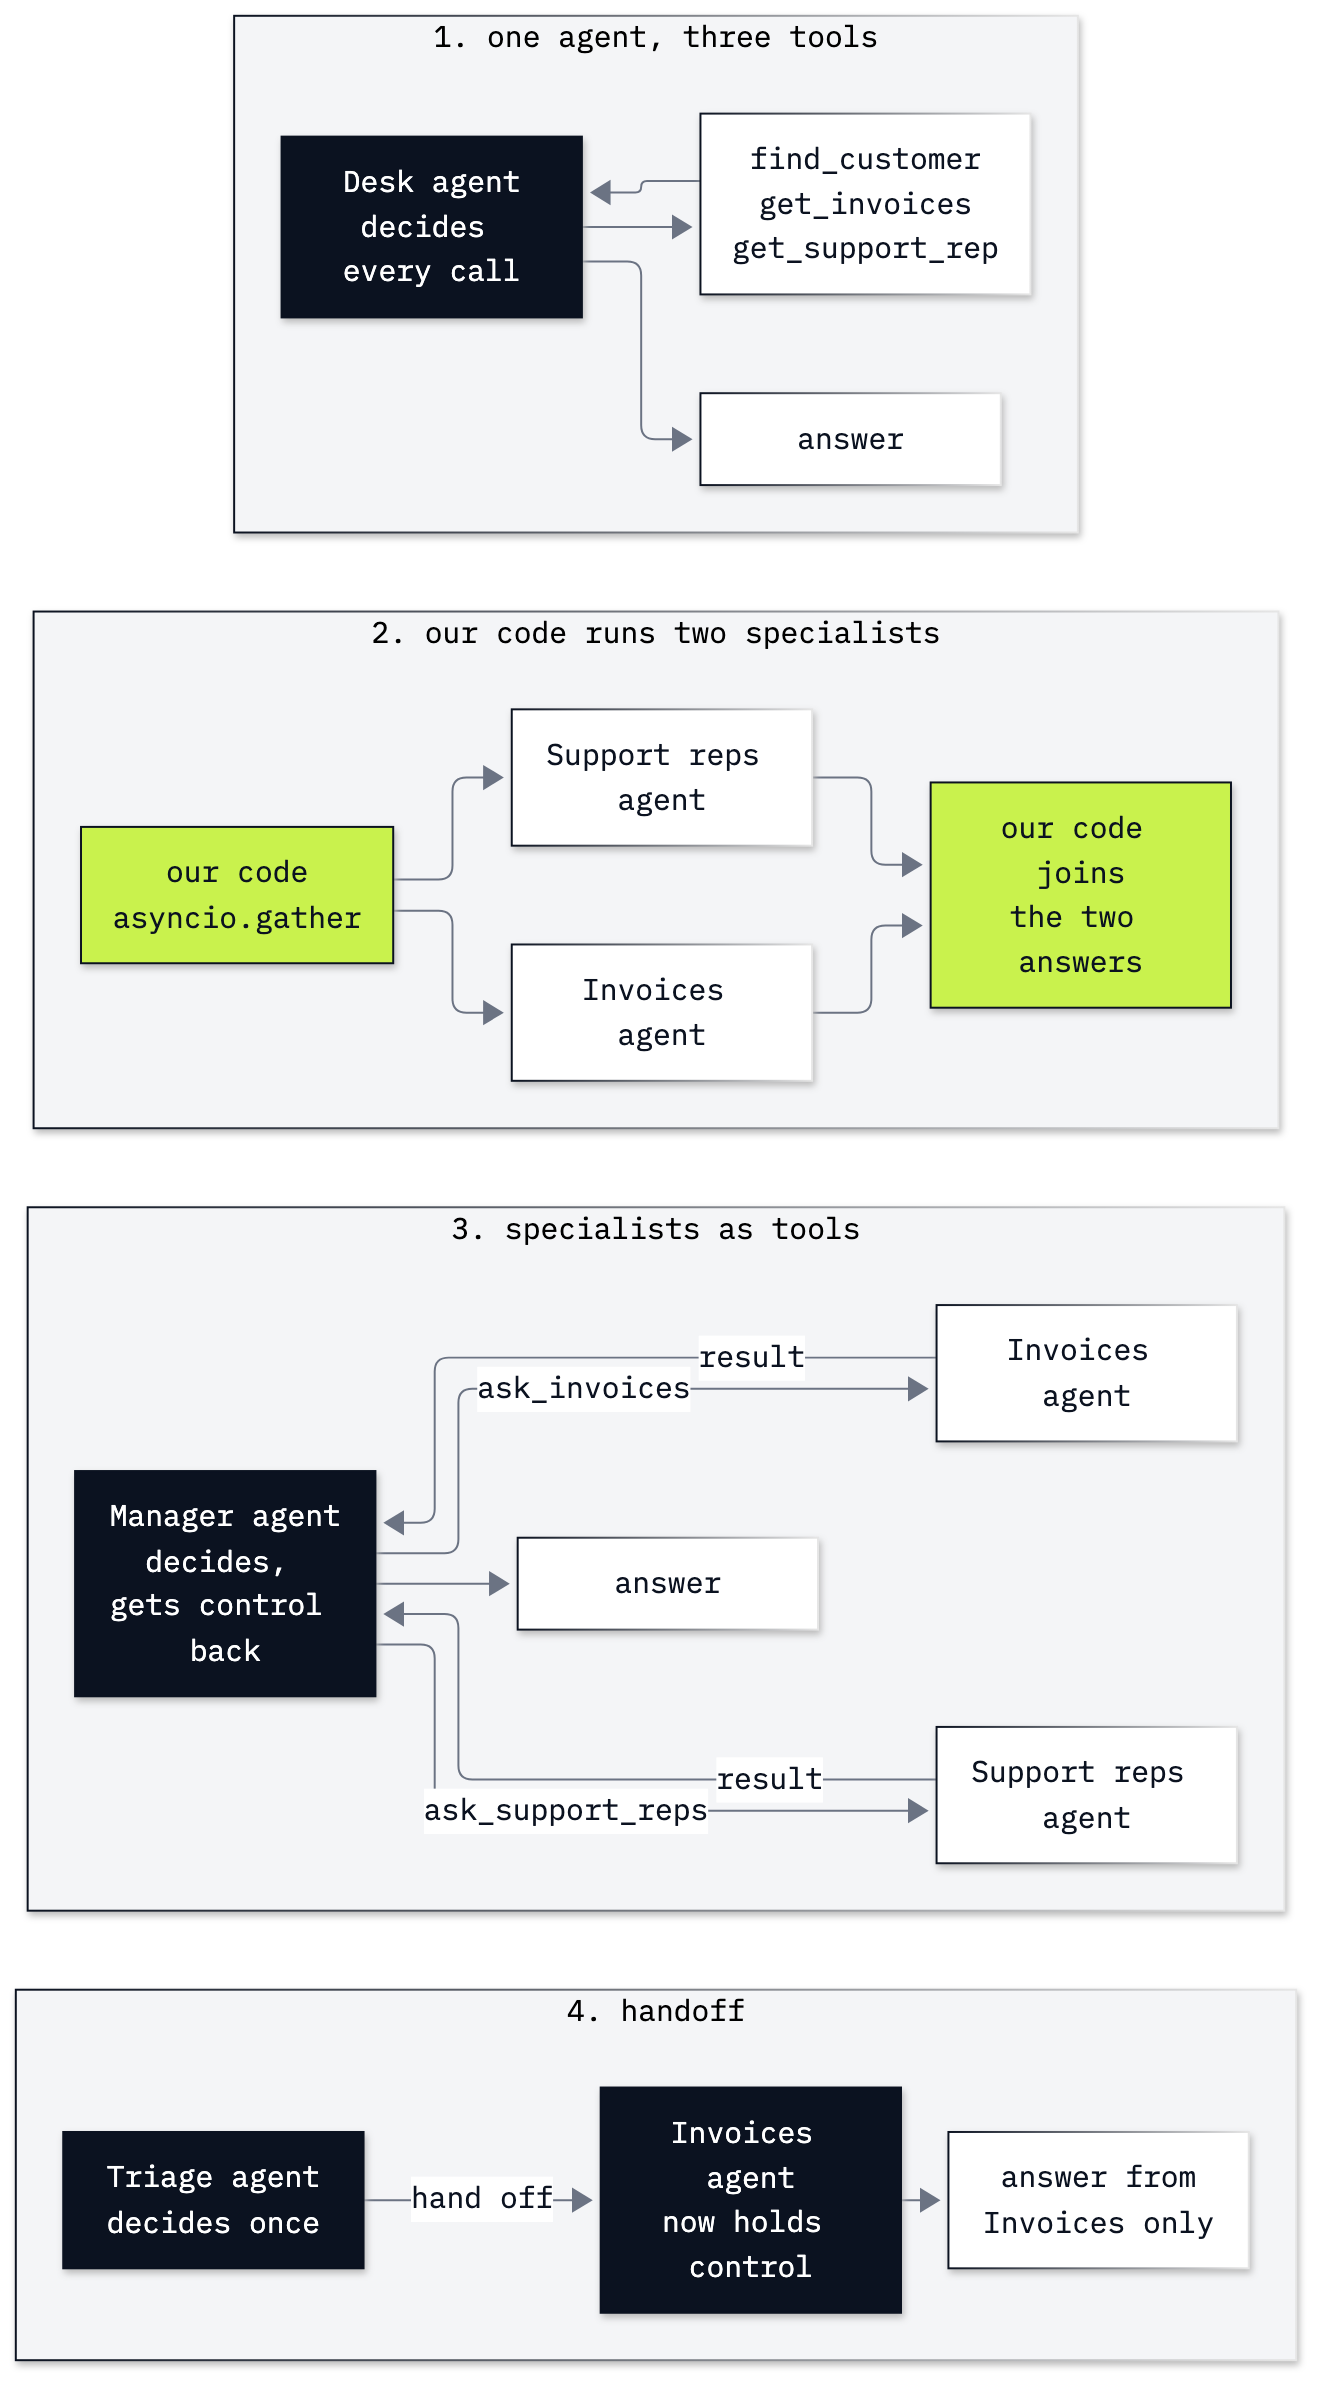

In [33]:
from IPython.display import Image

Image(filename="resources/lab07_wirings.png", width=760)

The question needs both halves: the invoices (count and total) and the support rep. The right answer, from Part B:
**6 invoices, $36.64, Jane Peacock.** `facts_found` checks a reply for the three; `\b` in the pattern is a word
boundary, so `6` must stand alone and is not found inside `36.64`.

In [34]:
PUJA = "How many invoices does Puja Srivastava have, what do they add up to, and who is her support rep?"
PUJA_FACTS = ["6", "36.64", "Jane Peacock"]


def facts_found(text):
    return [bool(re.search(rf"\b{re.escape(fact)}\b", text)) for fact in PUJA_FACTS]


print(facts_found("Puja Srivastava has 6 invoices totaling $36.64; her rep is Jane Peacock."))
print(facts_found("Puja Srivastava has 6 invoices totaling $36.64."))

[True, True, True]
[True, True, False]


### Wiring 1: one agent with all three tools

In [35]:
one = await Runner.run(desk, PUJA)
print(one.final_output)
print("facts:", facts_found(one.final_output), "| requests:", one.context_wrapper.usage.requests,
      "| input tokens:", one.context_wrapper.usage.input_tokens)

Puja Srivastava has 6 invoices, totaling $36.64. Her support rep is Jane Peacock.
facts: [True, True, True] | requests: 3 | input tokens: 858


All three facts in 3 requests and 858 input tokens: the baseline every other wiring is measured against.

### Two specialists

Each specialist is an ordinary `Agent` with only the tools for its part: **Invoices** can find a customer and read
their invoices; **Support reps** can find a customer and name their rep. Neither can do the other's job.
`handoff_description` is a sentence about the agent that another agent reads when deciding whether to hand off to it
(wiring 4 uses it).

In [36]:
invoices_agent = Agent(
    name="Invoices",
    handoff_description="Answers questions about a customer's invoices: how many, and their total.",
    instructions=("You answer questions about a customer's invoices. Look up every fact with your tools; "
                  "never answer from memory. Answer in one or two sentences."),
    model=MODEL,
    tools=[find_customer_tool, function_tool(get_invoices)],
    model_settings=SETTINGS,
)

reps_agent = Agent(
    name="Support reps",
    handoff_description="Answers who a customer's support rep is.",
    instructions=("You answer who looks after a customer. Look up every fact with your tools; "
                  "never answer from memory. Answer in one or two sentences."),
    model=MODEL,
    tools=[find_customer_tool, function_tool(get_support_rep)],
    model_settings=SETTINGS,
)

print(invoices_agent.name, [tool.name for tool in invoices_agent.tools])
print(reps_agent.name, [tool.name for tool in reps_agent.tools])

Invoices ['find_customer', 'get_invoices']
Support reps ['find_customer', 'get_support_rep']


### Wiring 2: our code runs both specialists at once

The two halves do not depend on each other, so our code can split the question, run both specialists with Part A's
`gather`, and join the answers. No model decides anything about the wiring: we wrote the split.

In [37]:
t0 = time.perf_counter()
inv_result, rep_result = await asyncio.gather(
    Runner.run(invoices_agent, "How many invoices does Puja Srivastava have, and what do they add up to?"),
    Runner.run(reps_agent, "Who is Puja Srivastava's support rep?"),
)
joined = inv_result.final_output + " " + rep_result.final_output
print(joined)
print("facts:", facts_found(joined),
      "| requests:", inv_result.context_wrapper.usage.requests + rep_result.context_wrapper.usage.requests,
      "| seconds:", round(time.perf_counter() - t0, 2))

Puja Srivastava has 6 invoices totaling $36.64. Puja Srivastava’s support rep is Jane Peacock.
facts: [True, True, True] | requests: 6 | seconds: 5.46


All three facts, from 6 requests, and since the two ran at once, in 5.46 seconds for both: about as long
as the one agent's three calls took in Part C. The catch is in the first
line of the cell: our code knew the question's two halves in advance. A different question from the rep would need
different code. When a model has to work out the parts, it needs one of the next two wirings.

### Wiring 3: the specialists as tools

`agent.as_tool(tool_name, tool_description)` wraps a whole agent as a `FunctionTool`. When the manager calls it, the
SDK runs that agent (a full `Runner.run` of its own, with its own turns) on an `input` string the manager writes,
and returns the agent's final answer as the tool's result. The manager then carries on.

['ask_invoices', 'ask_support_reps']
{"description": "Default input schema for agent-as-tool calls.", "properties": {"input": {"title": "Input", "type": "string"}}, "required": ["input"], "title": "AgentAsToolInput", "type": "object", "additionalProperties": false}


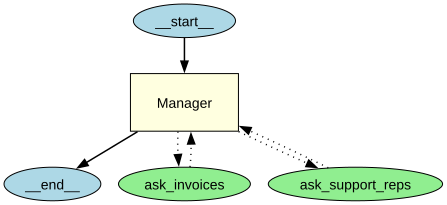

In [38]:
manager = Agent(
    name="Manager",
    instructions=("You help the support reps of a music shop. Ask the specialists for every fact; never answer from "
                  "memory. Answer in one or two sentences."),
    model=MODEL,
    tools=[
        invoices_agent.as_tool(
            tool_name="ask_invoices",
            tool_description="Ask the invoices specialist about a customer's invoices: how many, and their total.",
        ),
        reps_agent.as_tool(
            tool_name="ask_support_reps",
            tool_description="Ask the support-rep specialist who looks after a customer.",
        ),
    ],
    model_settings=SETTINGS,
)

print([tool.name for tool in manager.tools])
print(json.dumps(manager.tools[0].params_json_schema))
draw_graph(manager)

Each specialist became a tool with one string argument, `input`. In the drawing the specialists are green ellipses
(tools), with dotted arrows both ways like `Desk`'s lookups: the manager calls, the answer comes back to the manager.
The specialists' own lookups do not appear, because from the manager's side a specialist is one tool.

Before you run it: which agent will write the final answer?

In [39]:
recorder.spans.clear()
as_tools = await Runner.run(manager, PUJA)
print(as_tools.final_output)
print("facts:", facts_found(as_tools.final_output), "| last agent:", as_tools.last_agent.name,
      "| requests:", as_tools.context_wrapper.usage.requests,
      "| input tokens:", as_tools.context_wrapper.usage.input_tokens)
print()
for item in as_tools.new_items:
    if item.type == "tool_call_item":
        print("manager asked:", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        print("answer back:  ", item.output)

Puja Srivastava has 6 invoices totaling $36.64, and her support rep is Jane Peacock.
facts: [True, True, True] | last agent: Manager | requests: 8 | input tokens: 1787

manager asked: ask_invoices {"input":"How many invoices does Puja Srivastava have, and what is their total amount?"}
manager asked: ask_support_reps {"input":"Who is the support rep for Puja Srivastava?"}
answer back:   Puja Srivastava has 6 invoices totaling $36.64.
answer back:   Puja Srivastava’s support rep is Jane Peacock.


All three facts, written by the manager (`last agent: Manager`). The manager's `new_items` show what each specialist
was given: not the conversation, only the `input` the manager wrote, a question of its own
(`ask_invoices` got *How many invoices does Puja Srivastava have, and what is their total amount?*). The specialist answers that question; the manager reads the two answers and writes the reply.

The manager's items stop at the specialists' answers. Their own lookups ran in nested runs, which the trace shows:

In [40]:
show_trace(recorder.spans)

task      Agent workflow          12.63 s
    agent     Manager                 12.63 s
        turn                               8.78 s
            response                           3.07 s
            function  ask_invoices             5.71 s
                task      Agent workflow           5.71 s
                    agent     Invoices                 5.71 s
                        turn                               1.96 s
                            response                           1.96 s
                            function  find_customer            0.00 s
                        turn                               2.22 s
                            response                           2.21 s
                            function  get_invoices             0.00 s
                        turn                               1.52 s
                            response                           1.52 s
            function  ask_support_reps         5.10 s
                task      Agent 

Inside the manager's turns, each `function` span (`ask_invoices`, `ask_support_reps`) holds a whole run of its own:
a `task` and an `agent` span for the specialist, with its turns, its model calls and its lookups. Two things to read
in it:

- **The two specialists ran at the same time.** The manager asked for both in one reply, and the SDK ran the two tool calls together, as `gather` did in Part A. The manager's first turn took 8.78 seconds: its own model call (3.07) plus the longer specialist (5.71), not the 13.88 seconds the three would take one after the other (3.07 + 5.71 + 5.10).
- **The count.** One `response` span per model request: 8 in all, against 3 for one agent. `usage.requests`
  counts the same, because the SDK adds a nested run's usage to the run that called it. That is the price of
  control coming back: every specialist runs its own loop, and the manager needs a turn to call them and another to
  write the answer.

### Wiring 4: a handoff

A **handoff** passes the conversation to another agent, which takes over: it sees the whole conversation so far, and
its answer is the run's answer. The triage agent gets `handoffs=[...]` instead of tools; the SDK shows each handoff to
the model as a tool named `transfer_to_...`, described by the target's `handoff_description`.

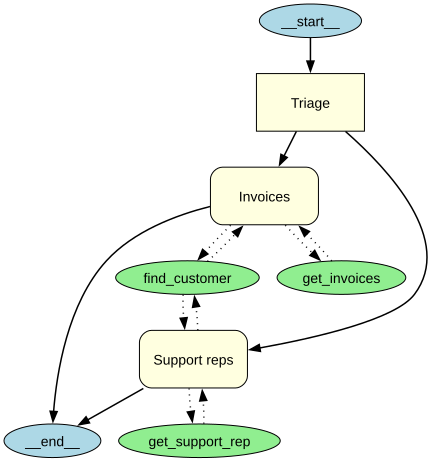

In [41]:
triage = Agent(
    name="Triage",
    instructions=("You route each request to the right specialist. Hand off to Invoices for invoice counts and "
                  "totals, and to Support reps for who looks after a customer."),
    model=MODEL,
    handoffs=[invoices_agent, reps_agent],
    model_settings=SETTINGS,
)

draw_graph(triage)

The drawing changes: the specialists are yellow boxes (agents in their own right, each with its green tools; the two share `find_customer`), and
the arrows from `Triage` to them are solid and one way. The arrows to `__end__` leave from the specialists: once a
specialist has the conversation, the run ends with its answer.

Before you run it: the question needs both specialists, and `Triage` can hand off to one. What will the answer hold?

In [42]:
recorder.spans.clear()
handed = await Runner.run(triage, PUJA)
print(handed.final_output)
print("facts:", facts_found(handed.final_output), "| last agent:", handed.last_agent.name,
      "| requests:", handed.context_wrapper.usage.requests,
      "| input tokens:", handed.context_wrapper.usage.input_tokens)
print()
for item in handed.new_items:
    if item.type == "handoff_output_item":
        print("handoff:", item.source_agent.name, "->", item.target_agent.name)
    elif item.type == "handoff_call_item":
        print("handoff asked:", item.raw_item.name)
    elif item.type == "tool_call_item":
        print("tool call:", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        print("result:", item.output)
print()
show_trace(recorder.spans)

Puja Srivastava has 6 invoices totaling $36.64. I couldn’t verify who her support rep is with the available tools.
facts: [True, True, False] | last agent: Invoices | requests: 4 | input tokens: 1101

handoff asked: transfer_to_invoices
handoff asked: transfer_to_support_reps
result: Multiple handoffs detected, ignoring this one.
handoff: Triage -> Invoices
tool call: find_customer {"name":"Puja Srivastava"}
result: [{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'}]
tool call: get_invoices {"customer_id":59}
result: {'customer_id': 59, 'invoice_count': 6, 'total': 36.64}

task      Agent workflow           7.58 s
    agent     Triage                   2.36 s
        turn                               2.36 s
            response                           2.36 s
            handoff   Triage -> Invoices       0.00 s  error: Multiple handoffs requested
    agent     Invoices                 5.22 s
        turn                               1.50 s
            response     

The reply: *Puja Srivastava has 6 invoices totaling $36.64. I couldn’t verify who her support rep is with the available tools.*

- `last agent` is `Invoices`: the run ended with the invoices specialist's answer.
- **The triage model did see both halves.** Its one reply asked for two handoffs, `transfer_to_invoices` and
  `transfer_to_support_reps`. A handoff gives the conversation to one agent, so the SDK took the first and answered
  the second with *Multiple handoffs detected, ignoring this one.* The trace marks the handoff span with the error
  *Multiple handoffs requested*.
- After the handoff, `Invoices` called `find_customer` and `get_invoices` and wrote the answer. `get_support_rep` was
  never called: no agent that held control had it.

Nothing stopped the run: no exception, a fluent reply, and two right facts. The rep is simply missing, because control moved to
an agent that cannot find it and **never came back** to anyone who could. That is what a handoff means: the target
takes over the conversation. It fits a request with one destination; it loses half of a request with two.

### Is that one run, or the rule? Five runs of each wiring

One run shows what can happen. Before we call it the rule, we run wirings 1, 3 and 4 five more times each and count. `handoffs asked`
counts the handoff requests among each run's items: `sum` over `True` and `False` values counts the `True`s.

In [43]:
WIRINGS = {"one agent": desk, "as tools": manager, "handoff": triage}
runs = []

for wiring, agent in WIRINGS.items():
    for run in range(1, 6):
        run_result = await Runner.run(agent, PUJA)
        found = facts_found(run_result.final_output)
        asked = sum(item.type == "handoff_call_item" for item in run_result.new_items)
        runs.append((wiring, run, run_result))
        print(f"{wiring:9} | run {run} | {' '.join('✅' if f else '❌' for f in found)} | "
              f"last agent {run_result.last_agent.name:8} | handoffs asked {asked} | "
              f"requests {run_result.context_wrapper.usage.requests} | "
              f"input tokens {run_result.context_wrapper.usage.input_tokens}")

one agent | run 1 | ✅ ✅ ✅ | last agent Desk     | handoffs asked 0 | requests 3 | input tokens 858


one agent | run 2 | ✅ ✅ ✅ | last agent Desk     | handoffs asked 0 | requests 3 | input tokens 858


one agent | run 3 | ✅ ✅ ✅ | last agent Desk     | handoffs asked 0 | requests 3 | input tokens 858


one agent | run 4 | ✅ ✅ ✅ | last agent Desk     | handoffs asked 0 | requests 3 | input tokens 858


one agent | run 5 | ✅ ✅ ✅ | last agent Desk     | handoffs asked 0 | requests 3 | input tokens 858


as tools  | run 1 | ✅ ✅ ✅ | last agent Manager  | handoffs asked 0 | requests 8 | input tokens 1795


... (5 outputs left out)

handoff   | run 2 | ✅ ✅ ❌ | last agent Invoices | handoffs asked 2 | requests 4 | input tokens 1101


handoff   | run 3 | ✅ ✅ ❌ | last agent Invoices | handoffs asked 2 | requests 4 | input tokens 1101


handoff   | run 4 | ✅ ✅ ❌ | last agent Invoices | handoffs asked 2 | requests 4 | input tokens 1101


handoff   | run 5 | ✅ ✅ ❌ | last agent Invoices | handoffs asked 2 | requests 4 | input tokens 1101


The three marks are the three facts in order: invoice count, total, rep. Every reply with a ❌, in full:

In [44]:
for wiring, run, run_result in runs:
    if not all(facts_found(run_result.final_output)):
        print(f"{wiring}, run {run} ({run_result.last_agent.name}): {run_result.final_output}")

handoff, run 1 (Invoices): Puja Srivastava has 6 invoices totaling $36.64. I don’t have a tool available to look up her support representative.
handoff, run 2 (Invoices): Puja Srivastava has 6 invoices totaling $36.64. I couldn’t verify who her support rep is with the available tools.
handoff, run 3 (Invoices): Puja Srivastava has 6 invoices totaling $36.64. I couldn’t verify who her support rep is with the available lookup tools.
handoff, run 4 (Invoices): Puja Srivastava has 6 invoices totaling $36.64. I can’t verify who her support rep is with the available tools.
handoff, run 5 (Invoices): Puja Srivastava has 6 invoices totaling $36.64. I can’t determine her support rep from the available records.


Over these five runs each:

| Wiring | All three facts | Model requests per run | Input tokens per run | Who wrote the answer |
|---|---|---|---|---|
| one agent, three tools | 5 of 5 | 3 | 858 | Desk |
| specialists as tools | 5 of 5 | 8 | 1,787 to 1,803 | Manager |
| handoff | 0 of 5 | 4 | 1,101 | Invoices |

Notice the handoff rows: in all five the triage asked for both handoffs, the SDK took the first, and the reply had the invoices without the rep. The failure is the design, not bad luck: a handoff passes the whole question to one specialist, and the invoices
specialist has no rep tool. The specialists as tools are right, but cost 8 requests and about
twice the input tokens of one agent, for a question one agent answers alone. A second agent has to earn
that cost (lab 16 measures when it does).

### Where a handoff fits: a question with one destination

The same triage agent, asked only for the rep:

In [45]:
rep_only = await Runner.run(triage, "Who is Puja Srivastava's support rep?")
print(rep_only.final_output)
print("last agent:", rep_only.last_agent.name, "| requests:", rep_only.context_wrapper.usage.requests)

Puja Srivastava’s support rep is Jane Peacock.
last agent: Support reps | requests: 4


`Triage` handed off to `Support reps`, which looked up the rep and answered: one destination, a complete answer. Handoffs
suit a front desk that sends each request to the one team that owns it (billing, technical support, a language), and
where the specialist should talk to the customer directly from then on.

### Who decides the next step

| Wiring | Who decides what runs next | Does control come back? | Good when |
|---|---|---|---|
| one agent, three tools | the agent's model | it never leaves | the tools fit in one prompt: the default |
| our code runs specialists | our code | our code holds it throughout | the steps are known in advance; the same path every time |
| specialists as tools | the manager's model | yes, after each specialist | a question with several parts, one voice for the answer |
| handoff | the triage model, once | no: the specialist takes over | one destination per request |

**Checkpoint F.** One agent: three facts, 3 requests. Our code: three facts from two specialists run at once. As
tools: three facts, about 8 requests, nested specialist runs in the trace, `last_agent` `Manager`. Handoff: the
rep missing, `last_agent` `Invoices`, no `get_support_rep` call; the rep-only question answered by `Support reps`.

---

## In production

- **Traces leave the notebook.** The default processor uploads to the OpenAI dashboard; `add_trace_processor` adds an
  exporter beside it, and observability tools (MLflow, used in lab 18; Langfuse; Logfire; LangSmith, in bonus B8)
  read the SDK's spans. Traces hold inputs and outputs, customer names included: decide where they may go
  (`RunConfig(trace_include_sensitive_data=False)` keeps model and tool inputs out of the spans).
- **Writes need approval.** A `function_tool` can be created with `needs_approval=True`, so a run pauses before it and
  resumes after a person agrees; guardrails check inputs and outputs. Bonus B2 puts both on this desk.
- **Sessions in a database server.** `SQLiteSession` suits one machine; the SDK has other session classes (for
  example on SQLAlchemy or Redis) for an application with several servers.

## What you can do now

- Explain what `async def`, `await` and `asyncio.gather` do, and run two independent model calls at once with
  `AsyncOpenAI` (Part A).
- Turn typed, documented functions into tools with `function_tool`, and read the schema it generates (Part B).
- Run an `Agent` with `Runner.run` and read the run as lab 04's loop: `new_items`, `raw_responses`, `usage` and a
  trace kept in the notebook (Part C).
- Set the reasoning effort with `ModelSettings` from `models.env`, and check the effort the API used in the trace
  (Part D).
- Keep a conversation across runs with `SQLiteSession`, and say what it stores and sends again (Part E).
- Wire specialists by code, as tools and as a handoff, and say who controls the next step and what each costs
  (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH` | `draw_graph` needs the Graphviz program, not only the Python package | install Graphviz (`sudo apt install -y graphviz` on Ubuntu, `brew install graphviz` on a Mac); the runs do not need it |
| `RuntimeError: AgentRunner.run_sync() cannot be called when an event loop is already running.` | `Runner.run_sync` starts its own event loop, and Jupyter already runs one | in a notebook, `await Runner.run(...)` |
| `RuntimeError: asyncio.run() cannot be called from a running event loop` | the same, for `asyncio.run` | `await` the coroutine directly in a notebook; keep `asyncio.run(main())` for `.py` files |
| `MaxTurnsExceeded: Max turns (1) exceeded` | the run reached `max_turns` before the model answered | raise `max_turns`, or find out why the model keeps calling tools |
| `gather` takes as long as running the calls one after another | a blocking call (`time.sleep`, the ordinary `OpenAI` client) inside `async def` | use `asyncio.sleep` and `AsyncOpenAI`, whose calls are awaited |
| a follow-up question answered as if it were the first | no session passed to the second `Runner.run` | pass the same `session=` to every run of the conversation |

## Challenge

1. **Let the specialists hand back.** Give `Invoices` and `Support reps` a handoff back to a triage agent, with one
   line in each specialist's instructions: if the request also asks for something its tools cannot look up, hand
   off to Triage with what is still missing; and one line in the triage's: when a specialist hands back, hand off to
   the specialist for what is still missing. (Make copies with `agent.clone(...)`, then set each copy's `handoffs`
   after all three exist, since each refers to the others.) Run the Puja question five times with `max_turns=12` and
   print, per run, the three facts, `last_agent`, the requests, the input tokens and the handoff path (from the
   `handoff_output_item`s in `new_items`). Expected: handoffs back and forth (`Triage -> Invoices -> Triage ->
   Support reps`), more requests and input tokens than the specialists as tools, and all three facts in most runs
   but not every one, because each handoff passes the conversation to an agent that decides for itself what to do
   with it. Compare with the specialists as tools.
2. **Carry a conversation through the manager.** Give the manager a `SQLiteSession` (under `outputs/`), ask the Puja
   question, then *And what about Helena Holý?* Expected: the second answer has 7, $49.62 and Steve Johnson, and the
   `input` the manager wrote for each specialist names Helena and the facts in full, since the specialists never see
   the session.

The worked solution, run with its outputs, is in `solved/07_openai_agents_sdk_solution.ipynb`.

## Resources

- [OpenAI Agents SDK](https://openai.github.io/openai-agents-python/): the documentation's home, with a quickstart
- [Agents](https://openai.github.io/openai-agents-python/agents/) and
  [Running agents](https://openai.github.io/openai-agents-python/running_agents/): `Agent`, `Runner.run`, the agent
  loop, `max_turns`
- [Tools](https://openai.github.io/openai-agents-python/tools/): `function_tool`, schemas from type hints and
  docstrings, agents as tools
- [Results](https://openai.github.io/openai-agents-python/results/): `final_output`, `new_items`, `raw_responses`,
  `last_agent`
- [Tracing](https://openai.github.io/openai-agents-python/tracing/): traces, spans and custom trace processors
- [Sessions](https://openai.github.io/openai-agents-python/sessions/): `SQLiteSession` and the other session classes
- [Handoffs](https://openai.github.io/openai-agents-python/handoffs/) and
  [Agent orchestration](https://openai.github.io/openai-agents-python/multi_agent/): handoffs, agents as tools and
  orchestration in code
- [Visualization](https://openai.github.io/openai-agents-python/visualization/): `draw_graph`
- [Python `asyncio`: coroutines and tasks](https://docs.python.org/3/library/asyncio-task.html): `await`, `gather`,
  `TaskGroup`
- [OpenAI: reasoning models](https://developers.openai.com/api/docs/guides/reasoning): reasoning effort and reasoning
  tokens